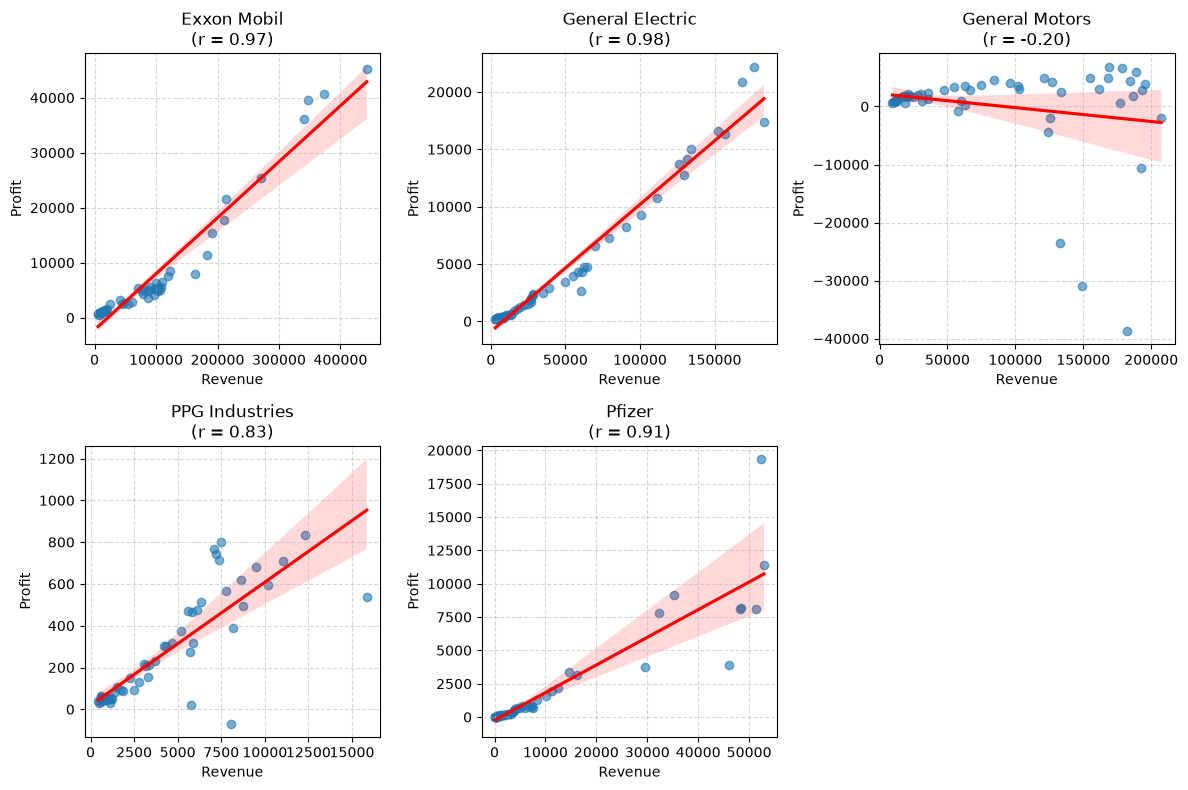

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

plt.figure(figsize=(12, 8))
for i, (company, group) in enumerate(df.groupby('Company'), 1):
    plt.subplot(2, 3, i)
    sns.regplot(
        data=group, 
        x='Revenue (in millions)', 
        y='Profit (in millions)', 
        scatter_kws={'alpha': 0.6}, 
        line_kws={'color': 'red'}
    )
    
    r, _ = pearsonr(group['Revenue (in millions)'], group['Profit (in millions)'])
    
    plt.title(f'{company}\n(r = {r:.2f})')
    plt.xlabel('Revenue')
    plt.ylabel('Profit')
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd

df = pd.read_excel(r"c:\python007\5_company.xlsx")

X = pd.get_dummies(
    df[['Revenue (in millions)', 'Rank', 'Year', 'Company']],
    columns=['Company'],
)
y = df['Profit (in millions)']

In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f'R-squared: {r2:.4f}')
print(f'MAE: {mae:.2f} Million USD')
print(f'RMSE: {rmse:.2f} Million USD')

R-squared: 0.6666
MAE: 1191.51 Million USD
RMSE: 3028.31 Million USD


In [11]:
df['Predicted_Profit'] = model.predict(X)

df['Residual'] = df['Profit (in millions)'] - df['Predicted_Profit']

outliers = df.sort_values(by='Residual', key=abs, ascending=False)
print(
    outliers[
        [
            'Year',
            'Company',
            'Revenue (in millions)',
            'Profit (in millions)',
            'Predicted_Profit',
            'Residual',
        ]
    ].head(10)
)

     Year           Company  Revenue (in millions)  Profit (in millions)  \
195  1994    General Motors               133621.9                2465.8   
266  2008    General Motors               182347.0              -38732.0   
263  2007            Pfizer                52415.0               19337.0   
272  2009    General Motors               148979.0              -30860.0   
190  1993    General Motors               132774.9              -23498.3   
261  2007    General Motors               207349.0               -1978.0   
200  1995    General Motors               154951.2                4900.6   
256  2006    General Motors               192604.0              -10600.0   
253  2005            Pfizer                52921.0               11361.0   
271  2009  General Electric               183207.0               17410.0   

     Predicted_Profit   Residual  
195        -13120.812  15586.612  
266        -24401.090 -14330.910  
263          7914.090  11422.910  
272        -22370.833  

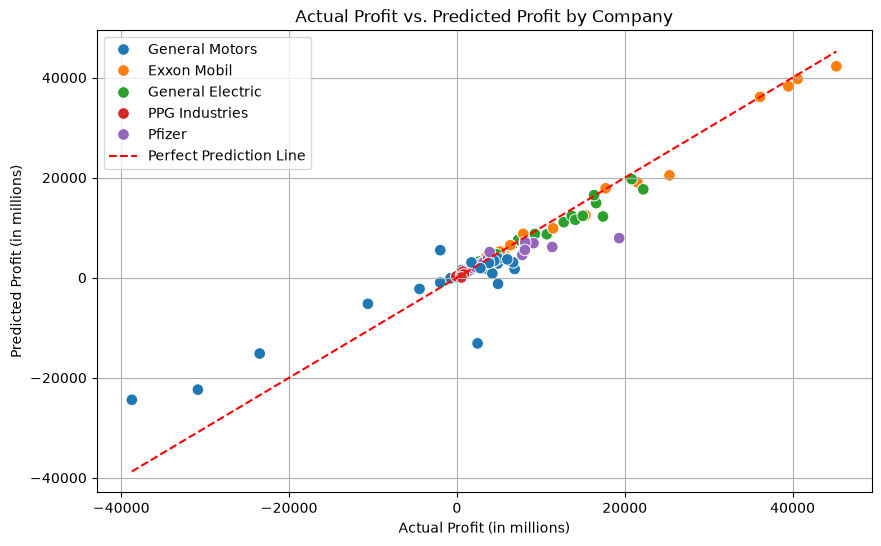

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Profit (in millions)',
    y='Predicted_Profit',
    hue='Company',
    s=70,
)
plt.plot(
    [df['Profit (in millions)'].min(), df['Profit (in millions)'].max()],
    [df['Profit (in millions)'].min(), df['Profit (in millions)'].max()],
    'r--',
    label='Perfect Prediction Line',
)
plt.title('Actual Profit vs. Predicted Profit by Company')
plt.xlabel('Actual Profit (in millions)')
plt.ylabel('Predicted Profit (in millions)')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
!pip install seaborn

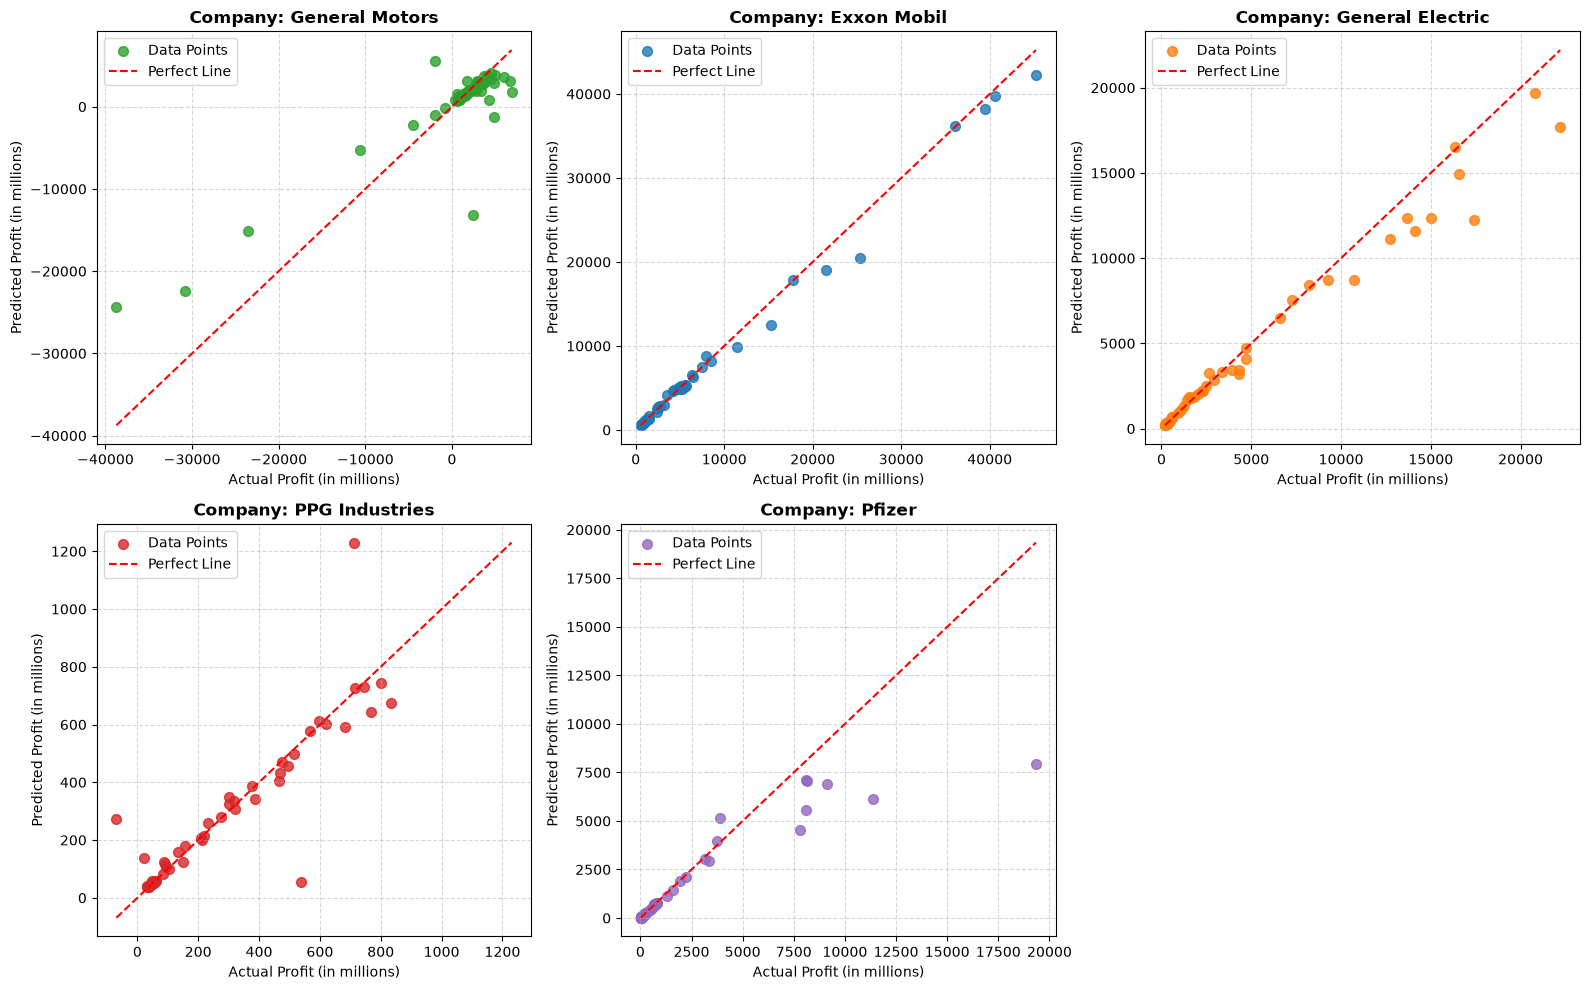

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

df = pd.read_excel(r"c:\python007\5_company.xlsx")
X = pd.get_dummies(df[['Revenue (in millions)', 'Rank', 'Year', 'Company']], columns=['Company'])
y = df['Profit (in millions)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

df['Predicted_Profit'] = model.predict(X)

companies = df['Company'].unique()
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

colors = {'Exxon Mobil': 'tab:blue', 'General Electric': 'tab:orange', 
          'General Motors': 'tab:green', 'PPG Industries': 'tab:red', 'Pfizer': 'tab:purple'}

for i, company in enumerate(companies):
    ax = axes[i]
    sub_df = df[df['Company'] == company]
    
    ax.scatter(sub_df['Profit (in millions)'], sub_df['Predicted_Profit'], 
               color=colors[company], alpha=0.8, s=50, label='Data Points')
    
    min_val = min(sub_df['Profit (in millions)'].min(), sub_df['Predicted_Profit'].min())
    max_val = max(sub_df['Profit (in millions)'].max(), sub_df['Predicted_Profit'].max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect Line')
    
    ax.set_title(f'Company: {company}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Actual Profit (in millions)')
    ax.set_ylabel('Predicted Profit (in millions)')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

fig.delaxes(axes[5])

plt.tight_layout()
plt.savefig('separated_companies_plot.png', dpi=300)
plt.show()

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

df = pd.read_excel(r"c:\python007\5_company.xlsx")

X = pd.get_dummies(df[['Revenue (in millions)', 'Rank', 'Year', 'Company']], columns=['Company'])
y = df['Profit (in millions)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

df['Predicted_Profit'] = model.predict(X)

results = []
for company in df['Company'].unique():
    sub_df = df[df['Company'] == company]
    r2 = r2_score(sub_df['Profit (in millions)'], sub_df['Predicted_Profit'])
    rmse = np.sqrt(mean_squared_error(sub_df['Profit (in millions)'], sub_df['Predicted_Profit']))
    mae = mean_absolute_error(sub_df['Profit (in millions)'], sub_df['Predicted_Profit'])
    results.append({
        'Company': company,
        'R2 Score': r2,
        'RMSE ($M)': rmse,
        'MAE ($M)': mae
    })

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))

         Company  R2 Score   RMSE ($M)    MAE ($M)
  General Motors  0.779212 3792.726012 1836.118200
     Exxon Mobil  0.991219  988.437774  445.913236
General Electric  0.960635 1182.588628  533.050382
  PPG Industries  0.803379  113.059095   46.038782
          Pfizer  0.744725 1826.678517  540.040218


In [19]:
import pandas as pd

excel_file = r"c:\python007\5_company.xlsx"

xls = pd.ExcelFile(excel_file)

print("Sheet names:", xls.sheet_names)

for sheet in xls.sheet_names:
    df = pd.read_excel(xls, sheet_name=sheet)
    print(f"\n--- Sheet: {sheet} ---")
    print(df.head())
    print(df.info())

Sheet names: ['Sheet1']

--- Sheet: Sheet1 ---
   Year  Rank           Company  Revenue (in millions)  Profit (in millions)
0  1955     1    General Motors                 9823.5                 806.0
1  1955     2       Exxon Mobil                 5661.4                 584.8
2  1955     4  General Electric                 2959.1                 212.6
3  1955    68    PPG Industries                  431.0                  38.6
4  1955   215            Pfizer                  145.2                  15.2
<class 'pandas.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   275 non-null    int64  
 1   Rank                   275 non-null    int64  
 2   Company                275 non-null    str    
 3   Revenue (in millions)  275 non-null    float64
 4   Profit (in millions)   275 non-null    float64
dtypes: float64(2), int64(2), str(

In [20]:
excel_file = r"d:\M\python\5_company.xlsx"
print("Years range:", df['Year'].min(), "to", df['Year'].max())
print("Companies included:", df['Company'].unique())

crisis_df = df[(df['Year'] >= 2006) & (df['Year'] <= 2011)]
print("\nCrisis Period Data (2006-2011):")
print(crisis_df.pivot(index='Year', columns='Company', values=['Revenue (in millions)', 'Profit (in millions)']))

Years range: 1955 to 2009
Companies included: <StringArray>
['General Motors', 'Exxon Mobil', 'General Electric', 'PPG Industries',
 'Pfizer']
Length: 5, dtype: str

Crisis Period Data (2006-2011):
        Revenue (in millions)                                                 \
Company           Exxon Mobil General Electric General Motors PPG Industries   
Year                                                                           
2006                 339938.0         157153.0       192604.0        10201.0   
2007                 347254.0         168307.0       207349.0        11037.0   
2008                 372824.0         176656.0       182347.0        12299.0   
2009                 442851.0         183207.0       148979.0        15849.0   

                 Profit (in millions)                                  \
Company   Pfizer          Exxon Mobil General Electric General Motors   
Year                                                                    
2006     51353.0      

In [21]:
import matplotlib.pyplot as plt

df_recent = df[df['Year'] >= 2000].copy()

profit_pivot = df_recent.pivot(index='Year', columns='Company', values='Profit (in millions)')
revenue_pivot = df_recent.pivot(index='Year', columns='Company', values='Revenue (in millions)')

print("Profit Pivot (2000-2009):")
print(profit_pivot)

print("\nRevenue Pivot (2000-2009):")
print(revenue_pivot)

profit_change = profit_pivot.pct_change() * 100
revenue_change = revenue_pivot.pct_change() * 100

print("\nProfit YoY % Change:")
print(profit_change.loc[2007:2009])

print("\nRevenue YoY % Change:")
print(revenue_change.loc[2007:2009])

Profit Pivot (2000-2009):
Company  Exxon Mobil  General Electric  General Motors  PPG Industries  \
Year                                                                     
2000          7910.0           10717.0          6002.0           568.0   
2001         17720.0           12735.0          4452.0           620.0   
2002         15320.0           13684.0           601.0           387.0   
2003         11460.0           14118.0          1736.0           -69.0   
2004         21510.0           15002.0          3822.0           494.0   
2005         25330.0           16593.0          2805.0           683.0   
2006         36130.0           16353.0        -10600.0           596.0   
2007         39500.0           20829.0         -1978.0           711.0   
2008         40610.0           22208.0        -38732.0           834.0   
2009         45220.0           17410.0        -30860.0           538.0   

Company   Pfizer  
Year              
2000      3179.0  
2001      3726.0  
2002     

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
for company in profit_pivot.columns:
    plt.plot(profit_pivot.index, profit_pivot[company], marker='o', label=company)

plt.title('Company Profit Trajectory (2000 - 2009)')
plt.xlabel('Year')
plt.ylabel('Profit (in millions USD)')
plt.axvline(x=2008, color='red', linestyle='--', alpha=0.7, label='Hamburger Crisis Peak (2008)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('profit_trajectory.png')
plt.close()

plt.figure(figsize=(10, 5))
for company in revenue_pivot.columns:
    plt.plot(revenue_pivot.index, revenue_pivot[company], marker='s', label=company)

plt.title('Company Revenue Trajectory (2000 - 2009)')
plt.xlabel('Year')
plt.ylabel('Revenue (in millions USD)')
plt.axvline(x=2008, color='red', linestyle='--', alpha=0.7, label='Hamburger Crisis Peak (2008)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('revenue_trajectory.png')
plt.close()

print("Charts saved.")

Charts saved.


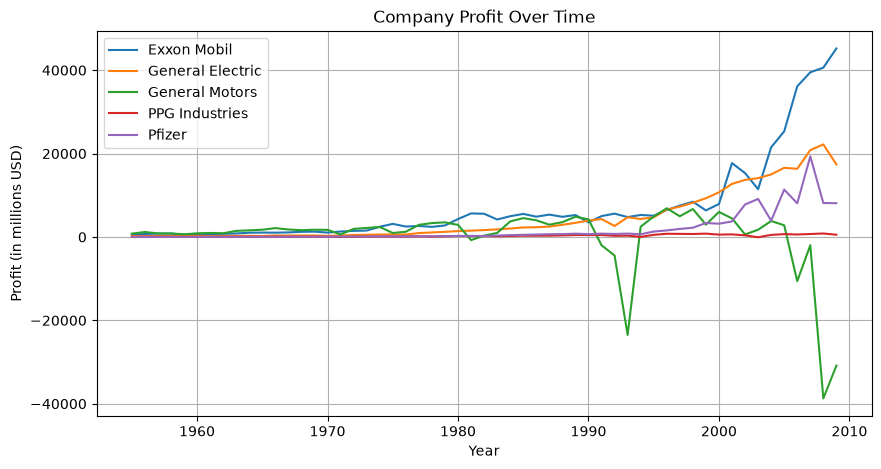

In [23]:
plt.figure(figsize=(10, 5))
for company, group in df.groupby("Company"):
    plt.plot(group["Year"], group["Profit (in millions)"], label=company)

plt.title("Company Profit Over Time")
plt.xlabel("Year")
plt.ylabel("Profit (in millions USD)")
plt.legend()
plt.grid(True)

plt.show()

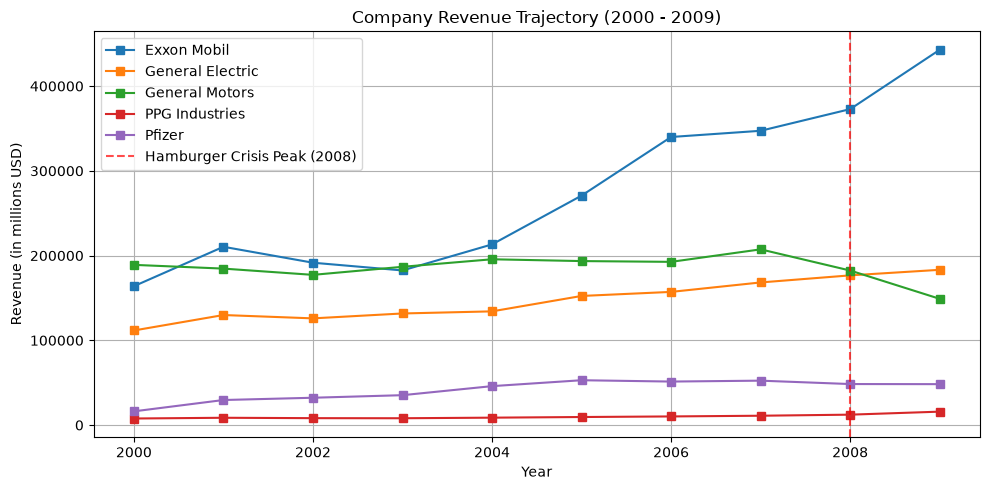

In [24]:
df_recent = df[df["Year"] >= 2000].copy()
revenue_pivot = df_recent.pivot(
    index="Year", columns="Company", values="Revenue (in millions)"
)

plt.figure(figsize=(10, 5))
for company in revenue_pivot.columns:
    plt.plot(
        revenue_pivot.index,
        revenue_pivot[company],
        marker="s",
        label=company,
    )

plt.title("Company Revenue Trajectory (2000 - 2009)")
plt.xlabel("Year")
plt.ylabel("Revenue (in millions USD)")
plt.axvline(
    x=2008,
    color="red",
    linestyle="--",
    alpha=0.7,
    label="Hamburger Crisis Peak (2008)",
)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("revenue_chart.png", dpi=300)

plt.show()